# Unrotated surface-code resizing

**[DEMO]** — Prepare → source SE → resize → readout, using the packaged logical operations.

The default is distance 5→3 shrink with no target SE. Change `OPERATION` to
`"enlarge"` for 3→5 growth, or set `ROUNDS = 1` to add one target SE round after
shrinking. Both keep the minimum-coordinate corner. Shrink measurements retain
the logical Pauli frame in the tracker; subsequent operations use the returned
patch. The circuit is noiseless.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lightstim").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from lightstim.ir.builder import CircuitBuilder
from lightstim.ir.logical_executor import LogicalExecutor
from lightstim.ir.qec_system import QECSystem
from lightstim.ir.tracker import SyndromeTracker
from lightstim.qec_code.surface_code.unrotated import (
    UnrotatedSurfaceCode,
    UnrotatedSurfaceCodeExtractionBlock,
    UnrotatedSurfaceCodeLogicalOpSet,
)

In [2]:
OPERATION = "shrink"  # "shrink" or "enlarge"
DISTANCE, TARGET_DISTANCE = (5, 3) if OPERATION == "shrink" else (3, 5)
DIRECTION = "-x,-y" if OPERATION == "shrink" else "+x,+y"
ROUNDS = 0 if OPERATION == "shrink" else 1  # Shrink: optional target SE; enlarge: all target SE.
SOURCE_ROUNDS = 1
INITIAL_BASIS = "X"  # "X" or "Z"

In [3]:
system = QECSystem()
patch = system.add_patch(UnrotatedSurfaceCode(distance=DISTANCE), name="patch")
tracker = SyndromeTracker(system.num_qubits, system.num_logicals)
builder = CircuitBuilder(tracker, system)
system.register_tracker(tracker)
system.register_builder(builder)
executor = LogicalExecutor(builder)
executor.register_op_set(
    UnrotatedSurfaceCode,
    UnrotatedSurfaceCodeLogicalOpSet(UnrotatedSurfaceCodeExtractionBlock),
)

before = patch.get_info()
builder.write_coordinates()
builder.initialize({q: INITIAL_BASIS for q in sorted(patch.data_indices)}, system.num_qubits)
source_se = UnrotatedSurfaceCodeExtractionBlock(system, scheduling="4tick")
builder.apply_syndrome_extraction(source_se.circuit, rounds=SOURCE_ROUNDS)

In [4]:
patch = executor.apply_logical_operation(
    OPERATION, [patch], target_distance=TARGET_DISTANCE, direction=DIRECTION, rounds=ROUNDS,
)
builder.apply_data_readout({q: INITIAL_BASIS for q in sorted(patch.data_indices)})
circuit = builder.to_stim_circuit()

In [5]:
after = patch.get_info()
registered = system.patches["patch"][0].get_info()

print(f"{'Patch':<17} {'d_X':>4} {'d_Z':>4} {'Data':>6} {'X checks':>9} {'Z checks':>9}")
for label, info in (("Before resize", before), ("After resize", after)):
    print(f"{label:<17} {info['distance_x']:>4} {info['distance_z']:>4} "
          f"{info['num_data_qubits']:>6} {info['num_x_syndromes']:>9} {info['num_z_syndromes']:>9}")
print(f"\nRegistered patch: d_X={registered['distance_x']}, d_Z={registered['distance_z']}")
for basis in ("X", "Z"):
    operator = next(op for op in after["logical_ops"] if op["type"] == basis)
    pauli = " * ".join(f"{axis}{q}" for q, axis in sorted(operator["pauli"].items()))
    print(f"Logical {basis}: {pauli}  (weight {len(operator['pauli'])})")

Patch              d_X  d_Z   Data  X checks  Z checks
Before resize        5    5     41        20        20
After resize         3    3     13         6         6

Registered patch: d_X=3, d_Z=3
Logical X: X4 * X22 * X40  (weight 3)
Logical Z: Z4 * Z5 * Z6  (weight 3)


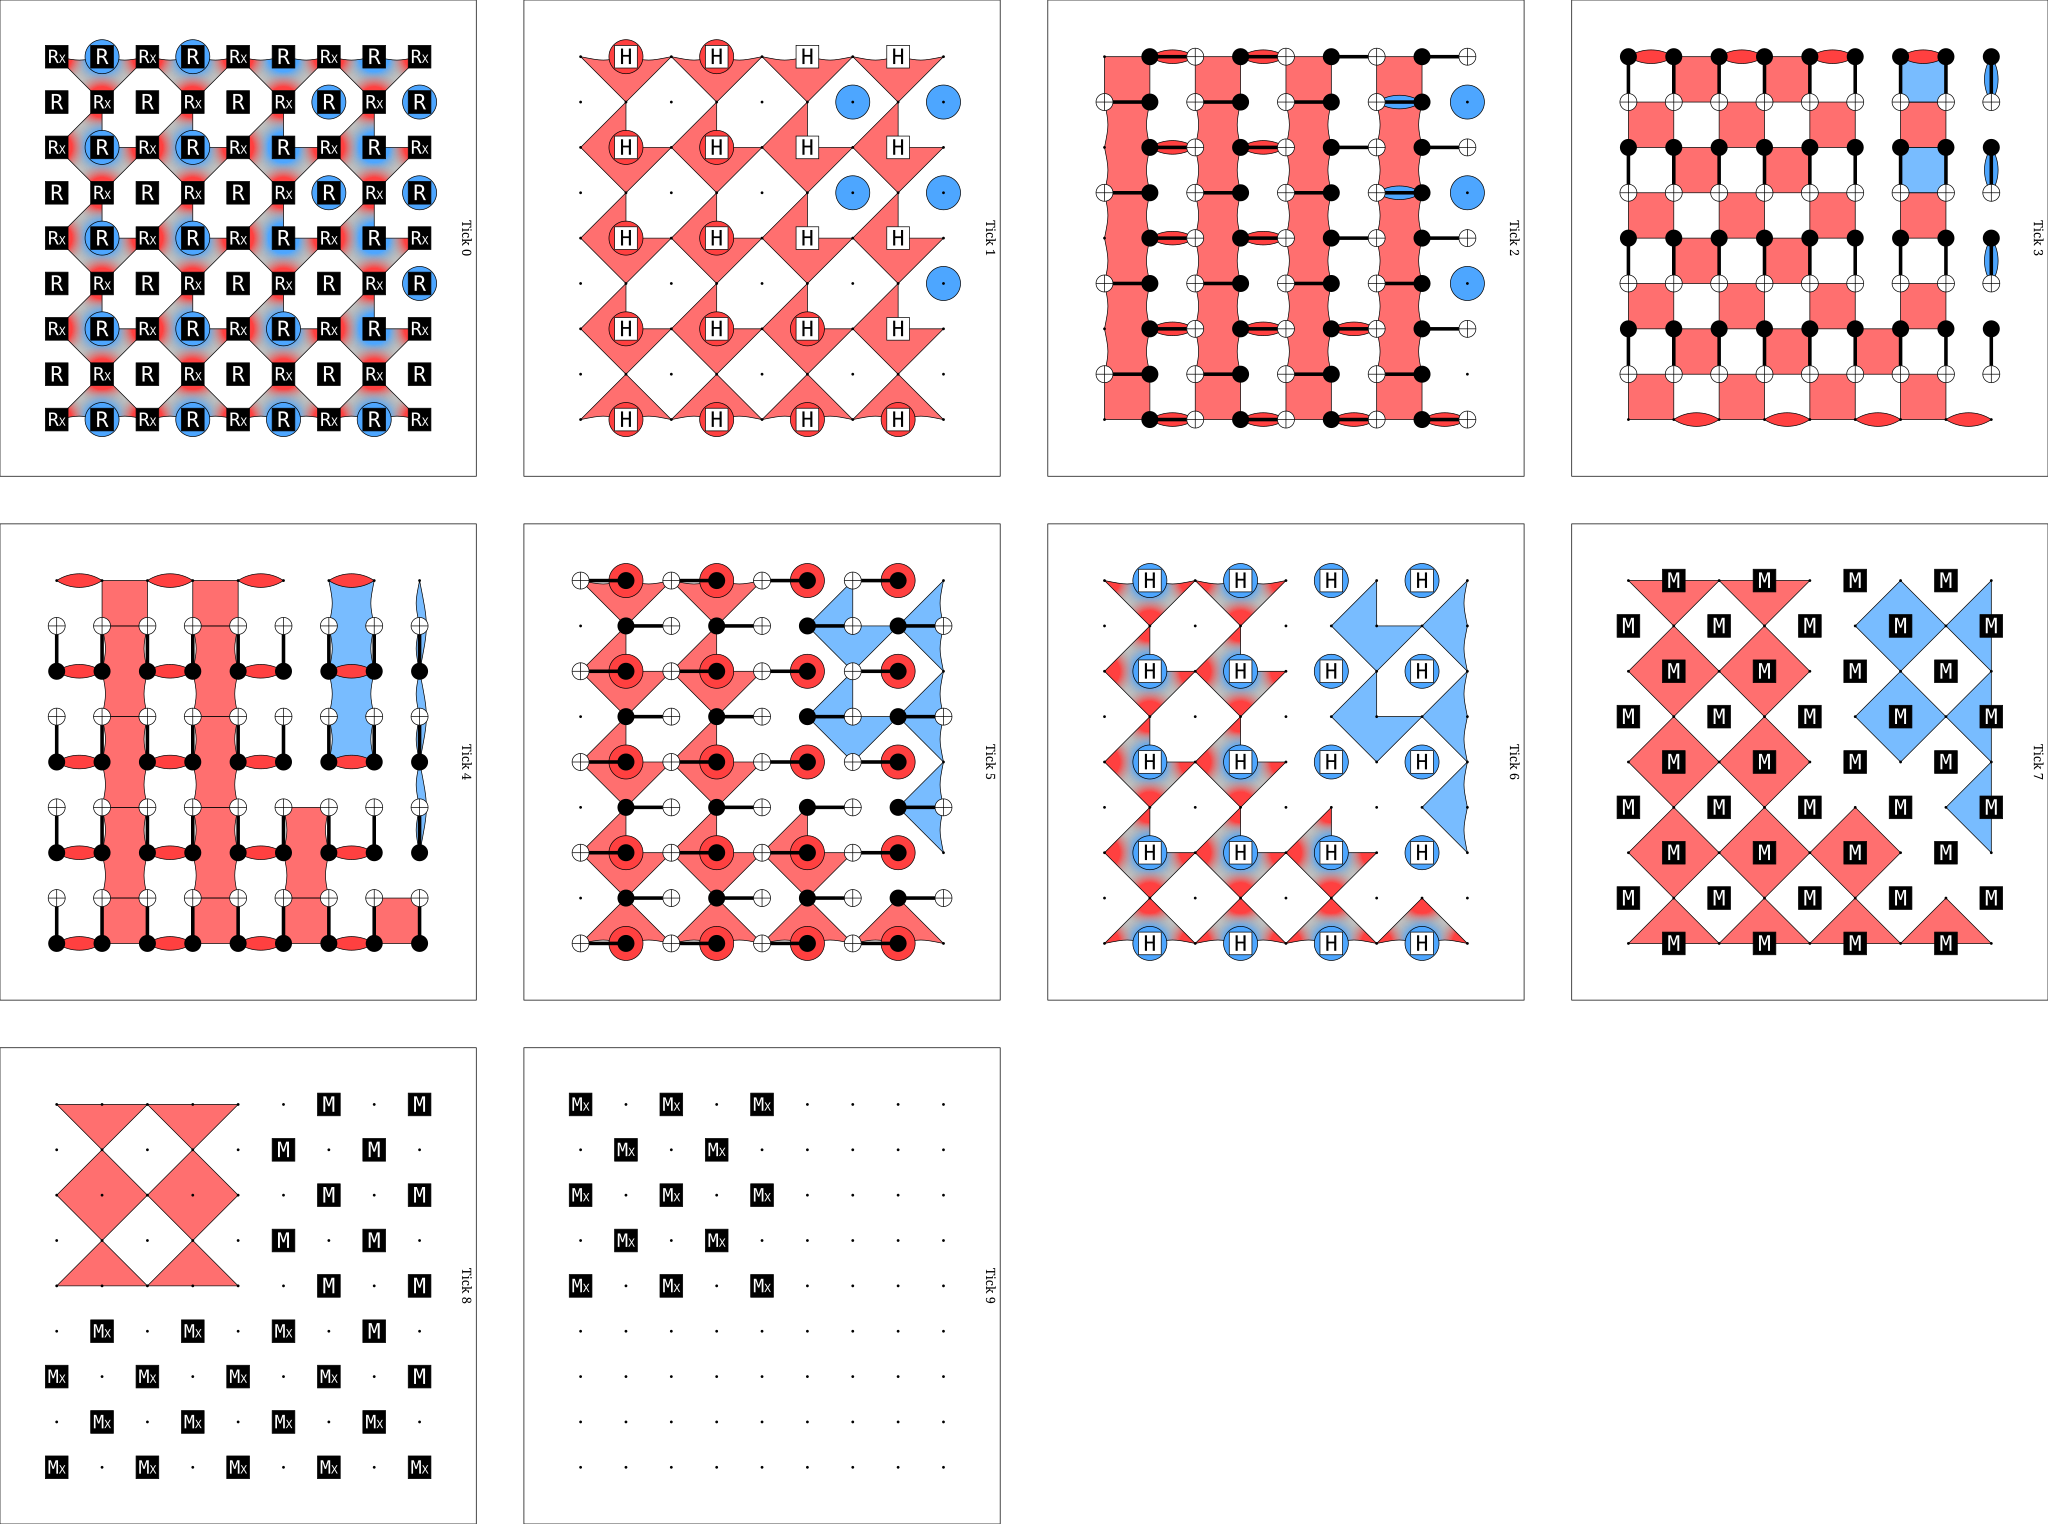

In [6]:
circuit.diagram("detslice-with-ops-svg")